# Praktikum 3 — Implementasi Algoritma Pencarian Buta dengan Python

**Mata Kuliah:** Kecerdasan Buatan (RPL3404) · **Program Studi:** D4 Teknologi Rekayasa Perangkat Lunak
**Jurusan Teknologi Informasi — Politeknik Negeri Padang** · Buku Ajar Bab 3: *Algoritma Pencarian Buta*

| Identitas | Isian |
|---|---|
| Nama | Windi SRi Rahayu |
| NIM | 2611089002 |
| Kelas | TRPL AK 1|
| Tanggal praktikum | 29 September 2026 |
| Tautan repositori Git | https://github.com/windyrahayu45/Kecerdasan-Buatan |

> Jalankan sel secara berurutan dari atas ke bawah (**Runtime → Run all** di Colab atau **Run All** di Jupyter/VS Code).

## A. Tujuan Praktikum
1. Merepresentasikan masalah pencarian (`Problem`) dan node pencarian (`Node`) sebagai kelas Python.
2. Mengimplementasikan BFS, UCS, DFS, depth-limited search (DLS), dan iterative deepening search (IDS).
3. Membandingkan rute, jumlah langkah, biaya, jumlah node yang di-expand, dan waktu eksekusi setiap algoritma.
4. Menerapkan antarmuka `Problem` yang sama pada masalah lain (8-puzzle) untuk menunjukkan generalitas algoritma.

## B. Alat dan Bahan
- Python 3.10+ (pustaka standar: `collections`, `heapq`, `time`)
- Opsional untuk visualisasi dan tabel: `networkx`, `matplotlib`, `pandas` (sudah tersedia di Google Colab)
- Buku Ajar Bab 3, terutama Gambar 3.1 dan Tabel 3.1–3.5

## C. Alokasi Waktu (2 jam praktik)
| Kegiatan | Durasi |
|---|---|
| Pengantar dan penyiapan lingkungan | 10 menit |
| Langkah 1–3: representasi masalah, BFS, UCS | 35 menit |
| Langkah 4–5: DFS, DLS, IDS | 30 menit |
| Langkah 6–7: eksperimen perbandingan dan 8-puzzle | 35 menit |
| Diskusi dan penyusunan kesimpulan | 10 menit |

In [1]:
# Cek versi Python dan pustaka opsional
import sys
print("Python", sys.version.split()[0])
try:
    import networkx, matplotlib, pandas
    print("networkx", networkx.__version__, "| matplotlib", matplotlib.__version__, "| pandas", pandas.__version__)
except ImportError as e:
    print("Pustaka opsional belum terpasang:", e, "-> jalankan: pip install networkx matplotlib pandas")

Python 3.12.4
networkx 3.2.1 | matplotlib 3.8.4 | pandas 2.2.2


## D. Langkah Kerja

### Langkah 1 — Representasi masalah
Graph peta disimpan sebagai *dictionary* bersarang: kunci luar adalah kota, nilai dalam adalah jarak (km) ke kota tetangga.
Kelas `Problem` membungkus komponen formal masalah pencarian (Tabel 3.1): **initial state, goal, ACTIONS, RESULT, ACTION-COST**.
Kelas `Node` menyimpan **STATE, PARENT, ACTION, PATH-COST** ditambah `depth` (Subbab 3.3.2).

> **Catatan:** urutan tetangga pada dictionary menentukan urutan node dibangkitkan. Jarak dibulatkan untuk ilustrasi, bukan data resmi.

In [3]:
from collections import deque
import heapq

PETA_SUMBAR = {
    "Padang":         {"Pariaman": 56, "Padang Panjang": 72, "Solok": 64, "Painan": 77},
    "Pariaman":       {"Padang": 56, "Lubuk Basung": 48, "Padang Panjang": 50},
    "Painan":         {"Padang": 77},
    "Lubuk Basung":   {"Pariaman": 48, "Bukittinggi": 56},
    "Padang Panjang": {"Padang": 72, "Pariaman": 50, "Batusangkar": 36, "Bukittinggi": 19},
    "Bukittinggi":    {"Padang Panjang": 19, "Lubuk Basung": 56, "Payakumbuh": 33},
    "Batusangkar":    {"Padang Panjang": 36, "Solok": 55, "Sawahlunto": 46, "Payakumbuh": 42},
    "Solok":          {"Padang": 64, "Batusangkar": 55, "Sawahlunto": 36},
    "Sawahlunto":     {"Solok": 36, "Batusangkar": 46, "Sijunjung": 50},
    "Payakumbuh":     {"Bukittinggi": 33, "Batusangkar": 42},
    "Sijunjung":        {"Sawahlunto": 50}
}

class Problem:
    """Masalah pencarian: initial state, goal, ACTIONS, RESULT, ACTION-COST."""
    def __init__(self, initial, goal, graph):
        self.initial, self.goal, self.graph = initial, goal, graph
    def actions(self, s):            # aksi = pindah ke kota tetangga
        return list(self.graph[s])
    def result(self, s, a):          # transition model
        return a
    def action_cost(self, s, a, s2):
        return self.graph[s][s2]
    def is_goal(self, s):
        return s == self.goal

class Node:
    def __init__(self, state, parent=None, action=None, path_cost=0):
        self.state, self.parent = state, parent
        self.action, self.path_cost = action, path_cost
        self.depth = 0 if parent is None else parent.depth + 1
    def __lt__(self, other):          # dibutuhkan heapq saat biaya sama
        return self.state < other.state

def expand(problem, node):
    s = node.state
    for a in problem.actions(s):
        s2 = problem.result(s, a)
        cost = node.path_cost + problem.action_cost(s, a, s2)
        yield Node(s2, node, a, cost)

def path_states(node):
    path = []
    while node is not None:
        path.append(node.state)
        node = node.parent
    return path[::-1]

Sebelum menjalankan algoritma, uji dulu representasi masalah. Pastikan `actions`, `result`, dan `action_cost` bekerja sesuai contoh pada Tabel 3.1.

In [4]:
masalah = Problem("Padang", "Sijunjung", PETA_SUMBAR)

print("ACTIONS(Padang)            =", masalah.actions("Padang"))
print("RESULT(Padang, Solok)      =", masalah.result("Padang", "Solok"))
print("ACTION-COST(Padang, Solok) =", masalah.action_cost("Padang", "Solok", "Solok"), "km")
print("IS-GOAL(Sijunjung)         =", masalah.is_goal("Sijunjung"))

# Cek bahwa setiap jalan bersifat dua arah dengan jarak yang sama
for a, tetangga in PETA_SUMBAR.items():
    for b, w in tetangga.items():
        assert PETA_SUMBAR[b][a] == w, f"Jarak {a}-{b} tidak simetris"
print("Graph valid: semua jalan dua arah dan simetris.")

ACTIONS(Padang)            = ['Pariaman', 'Padang Panjang', 'Solok', 'Painan']
RESULT(Padang, Solok)      = Solok
ACTION-COST(Padang, Solok) = 64 km
IS-GOAL(Sijunjung)         = True
Graph valid: semua jalan dua arah dan simetris.


**Visualisasi state space (Gambar 3.1).** Sel ini opsional; lewati jika `networkx`/`matplotlib` tidak tersedia.

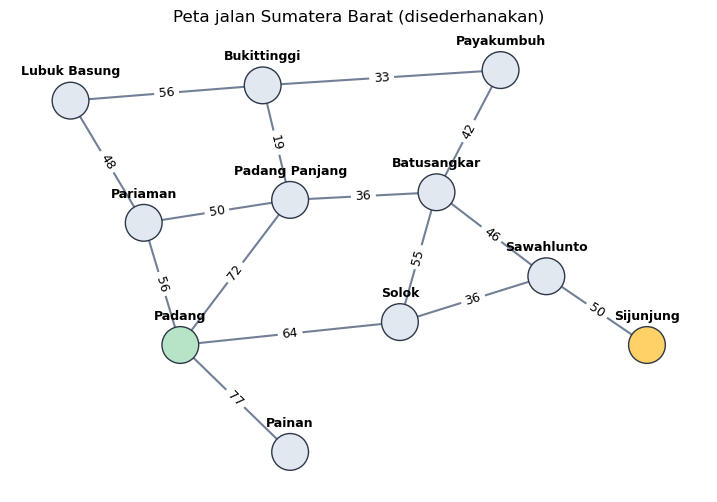

In [6]:
import matplotlib.pyplot as plt
import networkx as nx

POSISI = {"Lubuk Basung": (0.2, 4.2), "Pariaman": (1.0, 2.6), "Padang": (1.4, 1.0),
          "Painan": (2.6, -0.4), "Padang Panjang": (2.6, 2.9), "Bukittinggi": (2.3, 4.4),
          "Payakumbuh": (4.9, 4.6), "Batusangkar": (4.2, 3.0), "Solok": (3.8, 1.3),
          "Sawahlunto": (5.4, 1.9), "Sijunjung": (6.5, 1.0)}

def gambar_peta(graph, jalur=None, judul="Peta jalan Sumatera Barat (disederhanakan)"):
    G = nx.Graph()
    for a, nb in graph.items():
        for b, w in nb.items():
            G.add_edge(a, b, weight=w)
    fig, ax = plt.subplots(figsize=(9, 6))
    nx.draw_networkx_edges(G, POSISI, ax=ax, width=1.5, edge_color="#718096")
    if jalur:
        sisi = list(zip(jalur, jalur[1:]))
        nx.draw_networkx_edges(G, POSISI, edgelist=sisi, ax=ax, width=4, edge_color="#DD6B20")
    nx.draw_networkx_edge_labels(G, POSISI, edge_labels=nx.get_edge_attributes(G, "weight"), ax=ax, font_size=9)
    warna = ["#B7E4C7" if n == "Padang" else "#FFD166" if n == "Sijunjung" else "#E2E8F0" for n in G]
    nx.draw_networkx_nodes(G, POSISI, node_color=warna, node_size=700, edgecolors="#2D3748", ax=ax)
    nx.draw_networkx_labels(G, {k: (x, y + 0.38) for k, (x, y) in POSISI.items()}, font_size=9, font_weight="bold", ax=ax)
    ax.set_title(judul)
    ax.axis("off")
    plt.show()

gambar_peta(PETA_SUMBAR)

### Langkah 2 — Breadth-First Search (BFS)
BFS memakai **FIFO queue** (`deque`) dan himpunan `reached`. Goal diperiksa saat node dibangkitkan (**early goal test**).
Parameter `stats` adalah dictionary untuk menghitung jumlah node yang di-expand.

In [7]:
def breadth_first_search(problem, stats):
    node = Node(problem.initial)
    if problem.is_goal(node.state):
        return node
    frontier = deque([node])                 # FIFO queue
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    reached = {problem.initial}
    while frontier:
        node = frontier.popleft()
        stats["expanded"] += 1
        for child in expand(problem, node):
            s = child.state
            if problem.is_goal(s):           # early goal test
                return child
            if s not in reached:
                reached.add(s)
                frontier.append(child)
                stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return None

In [8]:
stats = {"expanded": 0}
hasil = breadth_first_search(masalah, stats)
print("Rute   :", " -> ".join(path_states(hasil)))
print("Langkah:", hasil.depth, "| Biaya:", hasil.path_cost, "km | Ekspansi:", stats["expanded"])

Rute   : Padang -> Solok -> Sawahlunto -> Sijunjung
Langkah: 3 | Biaya: 150 km | Ekspansi: 9


**Penelusuran BFS (bandingkan dengan Tabel 3.3).** Versi berikut sama dengan BFS di atas, tetapi mencetak isi frontier setiap iterasi.

In [9]:
def bfs_trace(problem):
    node = Node(problem.initial)
    frontier = deque([node])
    reached = {problem.initial}
    iterasi = 0
    while frontier:
        node = frontier.popleft()
        iterasi += 1
        baru = []
        for child in expand(problem, node):
            if problem.is_goal(child.state):
                print(f"{iterasi:>2}. expand {node.state:<15} -> GOAL {child.state}")
                return child
            if child.state not in reached:
                reached.add(child.state)
                frontier.append(child)
                baru.append(child.state)
        print(f"{iterasi:>2}. expand {node.state:<15} tambah {baru}")
        print(f"    frontier: {[n.state for n in frontier]}")
    return None

solusi = bfs_trace(masalah)
print("Solusi:", " -> ".join(path_states(solusi)))

 1. expand Padang          tambah ['Pariaman', 'Padang Panjang', 'Solok', 'Painan']
    frontier: ['Pariaman', 'Padang Panjang', 'Solok', 'Painan']
 2. expand Pariaman        tambah ['Lubuk Basung']
    frontier: ['Padang Panjang', 'Solok', 'Painan', 'Lubuk Basung']
 3. expand Padang Panjang  tambah ['Batusangkar', 'Bukittinggi']
    frontier: ['Solok', 'Painan', 'Lubuk Basung', 'Batusangkar', 'Bukittinggi']
 4. expand Solok           tambah ['Sawahlunto']
    frontier: ['Painan', 'Lubuk Basung', 'Batusangkar', 'Bukittinggi', 'Sawahlunto']
 5. expand Painan          tambah []
    frontier: ['Lubuk Basung', 'Batusangkar', 'Bukittinggi', 'Sawahlunto']
 6. expand Lubuk Basung    tambah []
    frontier: ['Batusangkar', 'Bukittinggi', 'Sawahlunto']
 7. expand Batusangkar     tambah ['Payakumbuh']
    frontier: ['Bukittinggi', 'Sawahlunto', 'Payakumbuh']
 8. expand Bukittinggi     tambah []
    frontier: ['Sawahlunto', 'Payakumbuh']
 9. expand Sawahlunto      -> GOAL Sijunjung
Solusi: Padang

### Langkah 3 — Uniform-Cost Search (UCS)
UCS memakai **priority queue** (`heapq`) yang diurutkan menurut path cost `g(n)`. Karena `heapq` tidak mendukung "perbarui prioritas",
node dengan biaya baru langsung dimasukkan; entri lama yang lebih mahal dilewati saat diambil (*lazy deletion*).
Goal diperiksa saat node diambil dari frontier (**late goal test**).

In [10]:
def uniform_cost_search(problem, stats):
    node = Node(problem.initial)
    frontier = [(0, node)]                   # priority queue (heap)
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    reached = {problem.initial: node}
    while frontier:
        g, node = heapq.heappop(frontier)
        if g > reached[node.state].path_cost:
            continue                         # entri usang, lewati
        if problem.is_goal(node.state):      # late goal test
            return node
        stats["expanded"] += 1
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                heapq.heappush(frontier, (child.path_cost, child))
                stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return None

In [11]:
stats = {"expanded": 0}
hasil = uniform_cost_search(masalah, stats)
print("Rute   :", " -> ".join(path_states(hasil)))
print("Langkah:", hasil.depth, "| Biaya:", hasil.path_cost, "km | Ekspansi:", stats["expanded"])

Rute   : Padang -> Solok -> Sawahlunto -> Sijunjung
Langkah: 3 | Biaya: 150 km | Ekspansi: 10


**Penelusuran UCS (bandingkan dengan Tabel 3.4).** Perhatikan kapan biaya Batusangkar diperbarui dan kapan Payakumbuh diakui sebagai goal.

In [12]:
def ucs_trace(problem):
    node = Node(problem.initial)
    frontier = [(0, node)]
    reached = {problem.initial: node}
    iterasi = 0
    while frontier:
        g, node = heapq.heappop(frontier)
        if g > reached[node.state].path_cost:
            print(f"    (lewati entri usang {node.state} = {g})")
            continue
        if problem.is_goal(node.state):
            print(f"{iterasi + 1:>2}. ambil {node.state} ({g}) -> GOAL")
            return node
        iterasi += 1
        catatan = []
        for child in expand(problem, node):
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                if s in reached:
                    catatan.append(f"    perbarui {s}: {reached[s].path_cost} -> {child.path_cost}")
                reached[s] = child
                heapq.heappush(frontier, (child.path_cost, child))
        isi = sorted((c, n.state) for c, n in frontier if c <= reached[n.state].path_cost)
        print(f"{iterasi:>2}. expand {node.state} ({g}) | frontier: " + ", ".join(f"{s} {c}" for c, s in isi))
        for teks in catatan:
            print(teks)
    return None

solusi = ucs_trace(masalah)
print("Solusi:", " -> ".join(path_states(solusi)), "=", solusi.path_cost, "km")

 1. expand Padang (0) | frontier: Pariaman 56, Solok 64, Padang Panjang 72, Painan 77
 2. expand Pariaman (56) | frontier: Solok 64, Padang Panjang 72, Painan 77, Lubuk Basung 104
 3. expand Solok (64) | frontier: Padang Panjang 72, Painan 77, Sawahlunto 100, Lubuk Basung 104, Batusangkar 119
 4. expand Padang Panjang (72) | frontier: Painan 77, Bukittinggi 91, Sawahlunto 100, Lubuk Basung 104, Batusangkar 108
    perbarui Batusangkar: 119 -> 108
 5. expand Painan (77) | frontier: Bukittinggi 91, Sawahlunto 100, Lubuk Basung 104, Batusangkar 108
 6. expand Bukittinggi (91) | frontier: Sawahlunto 100, Lubuk Basung 104, Batusangkar 108, Payakumbuh 124
 7. expand Sawahlunto (100) | frontier: Lubuk Basung 104, Batusangkar 108, Payakumbuh 124, Sijunjung 150
 8. expand Lubuk Basung (104) | frontier: Batusangkar 108, Payakumbuh 124, Sijunjung 150
 9. expand Batusangkar (108) | frontier: Payakumbuh 124, Sijunjung 150
    (lewati entri usang Batusangkar = 119)
10. expand Payakumbuh (124) | fron

### Langkah 4 — Depth-First Search (DFS)
DFS diimplementasikan sebagai **tree-like search** dengan `list` sebagai stack (LIFO). Fungsi `is_cycle` menelusuri rantai parent
untuk mencegah loop (pendekatan ketiga pada Subbab 3.3.3).

In [13]:
def is_cycle(node):
    s, p = node.state, node.parent
    while p is not None:
        if p.state == s:
            return True
        p = p.parent
    return False

def depth_first_search(problem, stats):
    frontier = [Node(problem.initial)]       # LIFO queue (stack)
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    while frontier:
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        stats["expanded"] += 1
        children = [c for c in expand(problem, node) if not is_cycle(c)]
        frontier.extend(reversed(children))  # tetangga pertama diproses dulu
        stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return None

In [14]:
stats = {"expanded": 0}
hasil = depth_first_search(masalah, stats)
print("Rute   :", " -> ".join(path_states(hasil)))
print("Langkah:", hasil.depth, "| Biaya:", hasil.path_cost, "km | Ekspansi:", stats["expanded"])

Rute   : Padang -> Pariaman -> Lubuk Basung -> Bukittinggi -> Padang Panjang -> Batusangkar -> Solok -> Sawahlunto -> Sijunjung
Langkah: 8 | Biaya: 356 km | Ekspansi: 8


### Langkah 5 — Depth-Limited Search (DLS) dan Iterative Deepening Search (IDS)
DLS mengembalikan node solusi, `None` (*failure*), atau `"cutoff"`. IDS memanggil DLS dengan batas kedalaman yang terus bertambah.

In [15]:
CUTOFF = "cutoff"

def depth_limited_search(problem, limit, stats):
    frontier = [Node(problem.initial)]
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    result = None                            # None berarti failure
    while frontier:
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        if node.depth >= limit:
            result = CUTOFF
        elif not is_cycle(node):
            stats["expanded"] += 1
            frontier.extend(reversed(list(expand(problem, node))))
            stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return result

def iterative_deepening_search(problem, stats):
    depth = 0
    while True:
        result = depth_limited_search(problem, depth, stats)
        if result != CUTOFF:
            return result
        depth += 1

In [67]:
# Amati hasil DLS untuk setiap batas kedalaman (Subbab 3.4.4)
for batas in range(5):
    st = {"expanded": 0}
    r = depth_limited_search(masalah, batas, st)
    keterangan = r if r in (None, CUTOFF) else " -> ".join(path_states(r))
    print(f"limit={batas}: {keterangan} | ekspansi={st['expanded']}")

stats = {"expanded": 0}
hasil = iterative_deepening_search(masalah, stats)
print("\nIDS:", " -> ".join(path_states(hasil)), "| biaya", hasil.path_cost, "km | total ekspansi", stats["expanded"])

limit=0: cutoff | ekspansi=0
limit=1: cutoff | ekspansi=1
limit=2: cutoff | ekspansi=5
limit=3: Padang -> Solok -> Sawahlunto -> Sijunjung | ekspansi=11
limit=4: Padang -> Padang Panjang -> Batusangkar -> Sawahlunto -> Sijunjung | ekspansi=13

IDS: Padang -> Solok -> Sawahlunto -> Sijunjung | biaya 150 km | total ekspansi 17


### Langkah 6 — Eksperimen perbandingan
Fungsi `jalankan` menjalankan satu algoritma dan mencetak rute, langkah, biaya, jumlah ekspansi, serta waktu.
Nilai waktu dapat berbeda pada setiap komputer.

In [16]:
import time

def jalankan(nama, fungsi, problem):
    stats = {"expanded": 0}
    t0 = time.perf_counter()
    hasil = fungsi(problem, stats)
    dt = (time.perf_counter() - t0) * 1000
    if hasil is None:
        print(f"{nama:<5} gagal menemukan solusi")
        return
    rute = " -> ".join(path_states(hasil))
    print(f"{nama:<5} | {rute}")
    print(f"      | langkah={hasil.depth}, biaya={hasil.path_cost} km, "
          f"ekspansi={stats['expanded']}, frontier maks={stats.get('max_frontier', 0)}, "
          f"waktu={dt:.3f} ms")

masalah = Problem("Padang", "Sijunjung", PETA_SUMBAR)
for nama, f in [("BFS", breadth_first_search),
                ("UCS", uniform_cost_search),
                ("DFS", depth_first_search),
                ("IDS", iterative_deepening_search)]:
    jalankan(nama, f, masalah)

BFS   | Padang -> Solok -> Sawahlunto -> Sijunjung
      | langkah=3, biaya=150 km, ekspansi=9, frontier maks=5, waktu=0.224 ms
UCS   | Padang -> Solok -> Sawahlunto -> Sijunjung
      | langkah=3, biaya=150 km, ekspansi=10, frontier maks=6, waktu=0.225 ms
DFS   | Padang -> Pariaman -> Lubuk Basung -> Bukittinggi -> Padang Panjang -> Batusangkar -> Solok -> Sawahlunto -> Sijunjung
      | langkah=8, biaya=356 km, ekspansi=8, frontier maks=8, waktu=0.199 ms
IDS   | Padang -> Solok -> Sawahlunto -> Sijunjung
      | langkah=3, biaya=150 km, ekspansi=17, frontier maks=7, waktu=0.390 ms


In [17]:
# Ringkasan dalam bentuk tabel (bandingkan dengan Tabel 3.8)
import pandas as pd

ALGORITMA = [("BFS", breadth_first_search), ("UCS", uniform_cost_search),
             ("DFS", depth_first_search), ("IDS", iterative_deepening_search)]

def bandingkan(problem, algoritma=ALGORITMA, ulang=200):
    baris = []
    for nama, f in algoritma:
        t0 = time.perf_counter()
        for _ in range(ulang):                      # diulang agar waktu lebih stabil
            stats = {"expanded": 0}
            hasil = f(problem, stats)
        dt = (time.perf_counter() - t0) / ulang * 1000
        baris.append({"Algoritma": nama,
                      "Rute": " - ".join(path_states(hasil)) if hasil else "-",
                      "Langkah": hasil.depth if hasil else None,
                      "Biaya (km)": hasil.path_cost if hasil else None,
                      "Node di-expand": stats["expanded"],
                      "Frontier maks": stats.get("max_frontier", 0),
                      "Waktu rata-rata (ms)": round(dt, 4)})
    return pd.DataFrame(baris)

tabel = bandingkan(masalah)
tabel

,Algoritma,Rute,Langkah,Biaya (km),Node di-expand,Frontier maks,Waktu rata-rata (ms)
0,BFS,Padang - Solok - Sawahlunto - Sijunjung,3,150,9,5,0.1617
1,UCS,Padang - Solok - Sawahlunto - Sijunjung,3,150,10,6,0.1749
2,DFS,Padang - Pariaman - Lubuk Basung - Bukittinggi...,8,356,8,8,0.1434
3,IDS,Padang - Solok - Sawahlunto - Sijunjung,3,150,17,7,0.2952


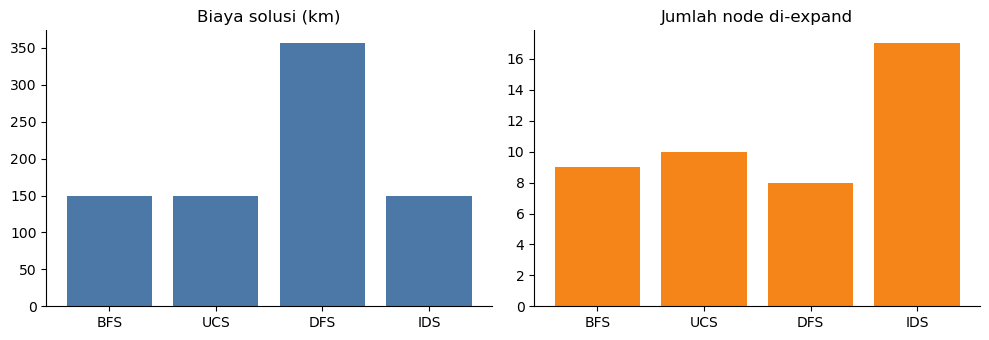

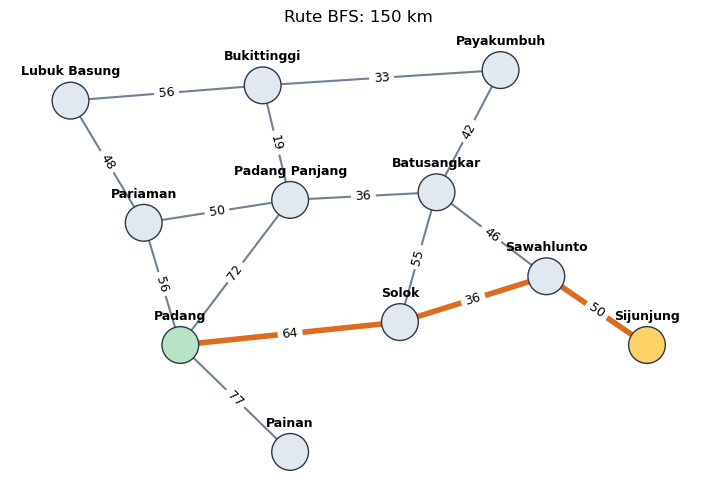

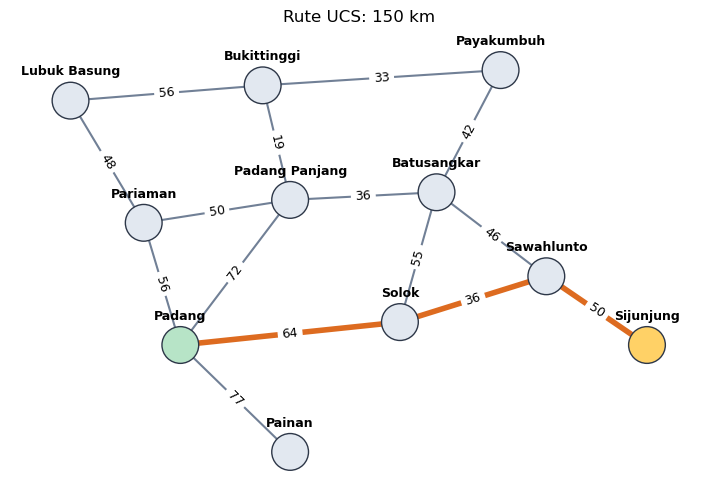

In [18]:
# Visualisasi: biaya dan jumlah ekspansi tiap algoritma
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(tabel["Algoritma"], tabel["Biaya (km)"], color="#4C78A8")
axes[0].set_title("Biaya solusi (km)")
axes[1].bar(tabel["Algoritma"], tabel["Node di-expand"], color="#F58518")
axes[1].set_title("Jumlah node di-expand")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# Tampilkan rute BFS dan UCS pada peta
for nama, f in [("BFS", breadth_first_search), ("UCS", uniform_cost_search)]:
    h = f(masalah, {"expanded": 0})
    gambar_peta(PETA_SUMBAR, path_states(h), f"Rute {nama}: {h.path_cost} km")

**Pertanyaan analisis Langkah 6** (jawab di sel Markdown di bawah):
1. Mengapa BFS dan UCS menghasilkan rute berbeda walaupun jumlah langkahnya sama?
2. Mengapa DFS menghasilkan rute yang jauh lebih panjang?
3. Mengapa IDS meng-expand lebih banyak node daripada BFS, tetapi tetap dianjurkan untuk state space besar?

*Jawaban:*

### Langkah 7 — Menerapkan algoritma yang sama pada 8-puzzle
Kelas `EightPuzzle` mewarisi `Problem` dan hanya mengganti `actions`, `result`, dan `action_cost`.
BFS dan IDS dipakai **tanpa perubahan**. State adalah tuple 9 angka dengan `0` sebagai ubin kosong.

In [19]:
class EightPuzzle(Problem):
    GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)          # 0 = ubin kosong
    GESER = {"Atas": -3, "Bawah": 3, "Kiri": -1, "Kanan": 1}
    def __init__(self, initial):
        self.initial, self.goal = tuple(initial), self.GOAL
    def actions(self, s):
        i = s.index(0)
        aksi = []
        if i >= 3: aksi.append("Atas")
        if i <= 5: aksi.append("Bawah")
        if i % 3 > 0: aksi.append("Kiri")
        if i % 3 < 2: aksi.append("Kanan")
        return aksi
    def result(self, s, a):
        i = s.index(0)
        j = i + self.GESER[a]
        s = list(s)
        s[i], s[j] = s[j], s[i]
        return tuple(s)
    def action_cost(self, s, a, s2):
        return 1

def cetak_papan(s):
    for r in range(3):
        print(" ".join("_" if v == 0 else str(v) for v in s[3*r:3*r+3]))

In [20]:
kasus = {"mudah":  (1, 2, 3, 4, 0, 6, 7, 5, 8),
         "sedang": (4, 1, 3, 7, 2, 6, 0, 5, 8),
         "sulit":  (3, 5, 0, 1, 4, 2, 7, 8, 6),
         "berat":  (1, 8, 3, 5, 0, 6, 4, 2, 7)}

baris = []
for nama, awal in kasus.items():
    for label, f in [("BFS", breadth_first_search), ("IDS", iterative_deepening_search)]:
        stats = {"expanded": 0}
        t0 = time.perf_counter()
        hasil = f(EightPuzzle(awal), stats)
        dt = (time.perf_counter() - t0) * 1000
        print(f"{nama:<7}{label}: langkah={hasil.depth}, ekspansi={stats['expanded']}")
        baris.append({"Kasus": nama, "Algoritma": label, "Langkah": hasil.depth,
                      "Node di-expand": stats["expanded"], "Waktu (ms)": round(dt, 2)})

tabel_puzzle = pd.DataFrame(baris)
tabel_puzzle

mudah  BFS: langkah=2, ekspansi=3
mudah  IDS: langkah=2, ekspansi=4
sedang BFS: langkah=6, ekspansi=32
sedang IDS: langkah=6, ekspansi=63
sulit  BFS: langkah=10, ekspansi=416
sulit  IDS: langkah=10, ekspansi=1126
berat  BFS: langkah=14, ekspansi=2680
berat  IDS: langkah=14, ekspansi=9301


,Kasus,Algoritma,Langkah,Node di-expand,Waktu (ms)
0,mudah,BFS,2,3,0.19
1,mudah,IDS,2,4,0.19
2,sedang,BFS,6,32,0.83
3,sedang,IDS,6,63,1.61
4,sulit,BFS,10,416,9.97
5,sulit,IDS,10,1126,27.16
6,berat,BFS,14,2680,227.06
7,berat,IDS,14,9301,167.20


In [21]:
# Tampilkan langkah-langkah solusi untuk kasus "sedang"
hasil = breadth_first_search(EightPuzzle(kasus["sedang"]), {"expanded": 0})
node, urutan = hasil, []
while node is not None:
    urutan.append(node)
    node = node.parent
for i, n in enumerate(reversed(urutan)):
    print(f"Langkah {i}: {n.action or 'awal'}")
    cetak_papan(n.state)
    print()

Langkah 0: awal
4 1 3
7 2 6
_ 5 8

Langkah 1: Atas
4 1 3
_ 2 6
7 5 8

Langkah 2: Atas
_ 1 3
4 2 6
7 5 8

Langkah 3: Kanan
1 _ 3
4 2 6
7 5 8

Langkah 4: Bawah
1 2 3
4 _ 6
7 5 8

Langkah 5: Bawah
1 2 3
4 5 6
7 _ 8

Langkah 6: Kanan
1 2 3
4 5 6
7 8 _



### Pengayaan — Pertumbuhan eksponensial node (Subbab 3.4.1 dan 3.4.4)
Rumus jumlah node yang dibangkitkan pada pohon seragam dengan branching factor *b* dan kedalaman solusi *d*:

- $N(BFS) = b + b^2 + \dots + b^d$
- $N(IDS) = (d)b + (d-1)b^2 + \dots + (1)b^d$

In [22]:
def ukuran(kb):
    for satuan in ["KB", "MB", "GB", "TB", "PB"]:
        if kb < 1000:
            return f"{kb:,.1f} {satuan}"
        kb /= 1000
    return f"{kb:,.1f} EB"

def n_bfs(b, d):
    return sum(b**i for i in range(1, d + 1))

def n_ids(b, d):
    return sum((d - i + 1) * b**i for i in range(1, d + 1))

print("b=10, d=5 -> N(IDS) =", f"{n_ids(10, 5):,}", "| N(BFS) =", f"{n_bfs(10, 5):,}")

baris = []
for d in range(2, 15, 2):
    bfs_n, ids_n = n_bfs(10, d), n_ids(10, d)
    baris.append({"d": d, "N(BFS)": bfs_n, "N(IDS)": ids_n,
                  "Tambahan IDS (%)": round((ids_n - bfs_n) / bfs_n * 100, 1),
                  "Memori BFS (1 KB/node)": ukuran(bfs_n)})
pd.DataFrame(baris)

b=10, d=5 -> N(IDS) = 123,450 | N(BFS) = 111,110


,d,N(BFS),N(IDS),Tambahan IDS (%),Memori BFS (1 KB/node)
0,2,110,120,9.1,110.0 KB
1,4,11110,12340,11.1,11.1 MB
2,6,1111110,1234560,11.1,1.1 GB
3,8,111111110,123456780,11.1,111.1 GB
4,10,11111111110,12345679000,11.1,11.1 TB
5,12,1111111111110,1234567901220,11.1,1.1 PB
6,14,111111111111110,123456790123440,11.1,111.1 PB


## E. Tugas Praktikum
Kerjakan setiap tugas di sel yang disediakan. Tambahkan sel baru bila perlu.

### Tugas 1
Ubah initial state dan goal menjadi **Painan → Lubuk Basung**. Jalankan keempat algoritma dan buat tabel perbandingan seperti Tabel 3.8.

In [23]:
masalah2 = Problem("Painan", "Lubuk Basung", PETA_SUMBAR)
tabel_tugas1 = bandingkan(masalah2)
tabel_tugas1

,Algoritma,Rute,Langkah,Biaya (km),Node di-expand,Frontier maks,Waktu rata-rata (ms)
0,BFS,Painan - Padang - Pariaman - Lubuk Basung,3,181,3,3,0.0233
1,UCS,Painan - Padang - Pariaman - Lubuk Basung,3,181,7,5,0.0460
2,DFS,Painan - Padang - Pariaman - Lubuk Basung,3,181,3,4,0.0181
3,IDS,Painan - Padang - Pariaman - Lubuk Basung,3,181,6,6,0.0571


### Tugas 2
Ubah urutan tetangga **Padang Panjang** sehingga `Bukittinggi` berada sebelum `Batusangkar`. Jalankan ulang BFS dan DFS, lalu jelaskan mengapa hasilnya berubah atau tidak berubah.

In [24]:
import copy
PETA_BARU = copy.deepcopy(PETA_SUMBAR)
PETA_BARU["Padang Panjang"] = {"Padang": 72, "Pariaman": 50, "Bukittinggi": 19, "Batusangkar": 36}
masalah3 = Problem("Padang", "Sijunjung", PETA_BARU)
for nama, fungsi in [("BFS", breadth_first_search), ("DFS", depth_first_search)]:
    stats = {"expanded": 0, "max_frontier": 0}
    hasil = fungsi(masalah3, stats)
    print(f"{nama}: {' -> '.join(path_states(hasil))} | langkah={hasil.depth} | "
          f"biaya={hasil.path_cost} km | ekspansi={stats['expanded']} | "
          f"frontier maks={stats['max_frontier']}")

BFS: Padang -> Solok -> Sawahlunto -> Sijunjung | langkah=3 | biaya=150 km | ekspansi=9 | frontier maks=5
DFS: Padang -> Pariaman -> Lubuk Basung -> Bukittinggi -> Padang Panjang -> Batusangkar -> Solok -> Sawahlunto -> Sijunjung | langkah=8 | biaya=356 km | ekspansi=8 | frontier maks=8


*Penjelasan Tugas 2:*

Pada graph ini, perubahan urutan tetangga Padang Panjang tidak mengubah rute yang ditemukan BFS maupun DFS. BFS tetap menemukan rute terdangkal melalui Solok dan Sawahlunto. DFS mencapai Padang Panjang melalui Bukittinggi; saat ekspansi, Bukittinggi sudah berada pada jalur induk sehingga dilewati oleh pemeriksaan siklus. Batusangkar tetap dapat dikunjungi, sehingga rute DFS pada contoh ini juga tetap sama. Urutan tetangga dapat memengaruhi urutan eksplorasi dan hasil DFS pada graph lain, tetapi tidak selalu mengubah hasil.

### Tugas 3
Tambahkan pengukuran **ukuran frontier maksimum** (`stats["max_frontier"]`) pada setiap algoritma sebagai pendekatan space complexity.
Bandingkan hasil BFS dan IDS pada kasus 8-puzzle "berat".

In [25]:
kasus_berat = EightPuzzle(kasus["berat"])
hasil_frontier = []
for nama, fungsi in [("BFS", breadth_first_search),
                     ("IDS", iterative_deepening_search)]:
    stats = {"expanded": 0, "max_frontier": 0}
    t0 = time.perf_counter()
    hasil = fungsi(kasus_berat, stats)
    waktu_ms = (time.perf_counter() - t0) * 1000
    hasil_frontier.append({
        "Algoritma": nama,
        "Langkah solusi": hasil.depth,
        "Node diekspansi": stats["expanded"],
        "Frontier maksimum": stats["max_frontier"],
        "Waktu (ms)": round(waktu_ms, 2),
    })

tabel_frontier = pd.DataFrame(hasil_frontier)
display(tabel_frontier)
print("BFS menyimpan frontier lebih besar, sedangkan IDS mengulang ekspansi tetapi "
      "menggunakan frontier maksimum yang jauh lebih kecil.")

,Algoritma,Langkah solusi,Node diekspansi,Frontier maksimum,Waktu (ms)
0,BFS,14,2680,1536,43.72
1,IDS,14,9301,22,140.33


BFS menyimpan frontier lebih besar, sedangkan IDS mengulang ekspansi tetapi menggunakan frontier maksimum yang jauh lebih kecil.


### Tugas 4
Implementasikan versi DFS yang menggunakan tabel `reached` (**graph search**). Bandingkan jumlah node yang di-expand dengan versi tree-like search.

In [26]:
def depth_first_graph_search(problem, stats):
    """DFS graph-search dengan state yang sudah ditemukan dicatat saat dibangkitkan."""
    awal = Node(problem.initial)
    if problem.is_goal(awal.state):
        stats["max_frontier"] = max(stats.get("max_frontier", 0), 1)
        return awal
    frontier = [awal]
    reached = {awal.state}
    stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    while frontier:
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        stats["expanded"] += 1
        children = []
        for child in expand(problem, node):
            if child.state not in reached:
                reached.add(child.state)
                children.append(child)
        frontier.extend(reversed(children))
        stats["max_frontier"] = max(stats.get("max_frontier", 0), len(frontier))
    return None

hasil_dfs = []
for nama, fungsi in [("DFS tree-like", depth_first_search),
                     ("DFS graph-search", depth_first_graph_search)]:
    stats = {"expanded": 0, "max_frontier": 0}
    hasil = fungsi(masalah, stats)
    hasil_dfs.append({
        "Algoritma": nama,
        "Rute": " -> ".join(path_states(hasil)),
        "Langkah": hasil.depth,
        "Biaya (km)": hasil.path_cost,
        "Node diekspansi": stats["expanded"],
        "Frontier maksimum": stats["max_frontier"],
    })

tabel_dfs = pd.DataFrame(hasil_dfs)
tabel_dfs

,Algoritma,Rute,Langkah,Biaya (km),Node diekspansi,Frontier maksimum
0,DFS tree-like,Padang -> Pariaman -> Lubuk Basung -> Bukittin...,8,356,8,8
1,DFS graph-search,Padang -> Pariaman -> Lubuk Basung -> Bukittin...,7,331,7,4


### Tugas 5 (Pengayaan)
Implementasikan **bidirectional breadth-first search** pada peta Sumatera Barat dan bandingkan jumlah node yang di-expand dengan BFS biasa.

In [27]:
def bidirectional_bfs(graph, start, goal, stats):
    """BFS dua arah pada graph tak berbobot; mengembalikan Node untuk rute terpendek."""
    if start not in graph or goal not in graph:
        raise ValueError("Kota awal dan tujuan harus ada di graph")
    stats.setdefault("expanded", 0)
    stats.setdefault("max_frontier", 0)
    if start == goal:
        stats["max_frontier"] = max(stats["max_frontier"], 1)
        return Node(start)

    frontier_start = deque([start])
    frontier_goal = deque([goal])
    parent_start = {start: None}
    parent_goal = {goal: None}
    stats["max_frontier"] = max(stats["max_frontier"], 2)
    perlebar_dari_awal = True
    temu = None

    while frontier_start and frontier_goal and temu is None:
        dari_awal = perlebar_dari_awal or not frontier_goal
        frontier = frontier_start if dari_awal else frontier_goal
        parent_sendiri = parent_start if dari_awal else parent_goal
        parent_lawan = parent_goal if dari_awal else parent_start
        for _ in range(len(frontier)):
            kota = frontier.popleft()
            stats["expanded"] += 1
            for tetangga in graph[kota]:
                if tetangga in parent_sendiri:
                    continue
                parent_sendiri[tetangga] = kota
                frontier.append(tetangga)
                stats["max_frontier"] = max(
                    stats["max_frontier"], len(frontier_start) + len(frontier_goal)
                )
                if tetangga in parent_lawan:
                    temu = tetangga
                    break
            if temu is not None:
                break
        perlebar_dari_awal = not perlebar_dari_awal

    if temu is None:
        return None

    sisi_awal = []
    kota = temu
    while kota is not None:
        sisi_awal.append(kota)
        kota = parent_start[kota]
    rute = list(reversed(sisi_awal))
    kota = parent_goal[temu]
    while kota is not None:
        rute.append(kota)
        kota = parent_goal[kota]

    problem = Problem(start, goal, graph)
    node = Node(start)
    for kota in rute[1:]:
        biaya = node.path_cost + problem.action_cost(node.state, kota, kota)
        node = Node(kota, node, kota, biaya)
    return node

stats_bfs_dua = {"expanded": 0, "max_frontier": 0}
hasil_bfs_dua = bidirectional_bfs(PETA_SUMBAR, "Padang", "Sijunjung", stats_bfs_dua)
stats_bfs_biasa = {"expanded": 0, "max_frontier": 0}
hasil_bfs_biasa = breadth_first_search(
    Problem("Padang", "Sijunjung", PETA_SUMBAR), stats_bfs_biasa
)
print("BFS biasa       :", " -> ".join(path_states(hasil_bfs_biasa)),
      f"| ekspansi={stats_bfs_biasa['expanded']}")
print("BFS dua arah    :", " -> ".join(path_states(hasil_bfs_dua)),
      f"| ekspansi={stats_bfs_dua['expanded']}")
print("Frontier maksimum gabungan BFS dua arah:", stats_bfs_dua["max_frontier"])
assert hasil_bfs_dua.depth == hasil_bfs_biasa.depth

BFS biasa       : Padang -> Solok -> Sawahlunto -> Sijunjung | ekspansi=9
BFS dua arah    : Padang -> Solok -> Sawahlunto -> Sijunjung | ekspansi=5
Frontier maksimum gabungan BFS dua arah: 6


### Tugas 6 (Pengayaan)
Bangun graph lokasi di lingkungan kampus PNP (minimal 12 node, misalnya gerbang, gedung jurusan, perpustakaan, masjid, kantin, parkiran)
dengan estimasi jarak berjalan kaki (meter). Gunakan UCS untuk mencari rute terpendek antara dua lokasi.

In [28]:
lokasi_kampus = [
    "Gerbang Utama", "Parkiran Utama", "Gedung Kuliah A", "Gedung Kuliah B",
    "Lab Komputer", "Gedung Jurusan TI", "Perpustakaan", "Masjid Kampus",
    "Kantin", "Auditorium", "Parkiran Belakang", "Lapangan", "Gerbang Samping",
]
KAMPUS_PNP = {lokasi: {} for lokasi in lokasi_kampus}
# Jarak berikut adalah estimasi ilustratif untuk praktikum, bukan pengukuran resmi kampus.
jalan_kampus = [
    ("Gerbang Utama", "Parkiran Utama", 80),
    ("Gerbang Utama", "Gedung Kuliah A", 150),
    ("Parkiran Utama", "Gedung Kuliah A", 90),
    ("Parkiran Utama", "Perpustakaan", 180),
    ("Gedung Kuliah A", "Gedung Kuliah B", 100),
    ("Gedung Kuliah A", "Lab Komputer", 70),
    ("Gedung Kuliah B", "Perpustakaan", 120),
    ("Gedung Kuliah B", "Gedung Jurusan TI", 80),
    ("Lab Komputer", "Gedung Jurusan TI", 60),
    ("Lab Komputer", "Kantin", 130),
    ("Gedung Jurusan TI", "Perpustakaan", 100),
    ("Gedung Jurusan TI", "Masjid Kampus", 140),
    ("Perpustakaan", "Masjid Kampus", 90),
    ("Perpustakaan", "Auditorium", 160),
    ("Masjid Kampus", "Kantin", 110),
    ("Masjid Kampus", "Auditorium", 100),
    ("Kantin", "Parkiran Belakang", 120),
    ("Auditorium", "Parkiran Belakang", 140),
    ("Parkiran Belakang", "Lapangan", 100),
    ("Lapangan", "Gerbang Samping", 130),
    ("Gerbang Samping", "Gerbang Utama", 200),
]
for lokasi_a, lokasi_b, jarak in jalan_kampus:
    KAMPUS_PNP[lokasi_a][lokasi_b] = jarak
    KAMPUS_PNP[lokasi_b][lokasi_a] = jarak

awal_kampus, tujuan_kampus = "Gerbang Utama", "Masjid Kampus"
masalah_kampus = Problem(awal_kampus, tujuan_kampus, KAMPUS_PNP)
stats_kampus = {"expanded": 0, "max_frontier": 0}
hasil_kampus = uniform_cost_search(masalah_kampus, stats_kampus)
print("Jumlah lokasi:", len(KAMPUS_PNP))
print("Rute terpendek:", " -> ".join(path_states(hasil_kampus)))
print("Jarak total:", hasil_kampus.path_cost, "meter")
print("Node diekspansi:", stats_kampus["expanded"],
      "| frontier maksimum:", stats_kampus["max_frontier"])
assert all(KAMPUS_PNP[b][a] == jarak for a, tetangga in KAMPUS_PNP.items()
           for b, jarak in tetangga.items())

Jumlah lokasi: 13
Rute terpendek: Gerbang Utama -> Parkiran Utama -> Perpustakaan -> Masjid Kampus
Jarak total: 350 meter
Node diekspansi: 10 | frontier maksimum: 5


## F. Kesimpulan
Tuliskan kesimpulan praktikum dengan mengaitkan hasil empiris pada sel-sel di atas dengan sifat **completeness, cost optimality, time complexity,
dan space complexity** pada Tabel 3.5 Buku Ajar.

*Kesimpulan:*

---
**Pernyataan penggunaan AI generatif** (isi jika ada, sesuai ketentuan RPS):

**Rujukan:** Russell, S. J., & Norvig, P. (2022). *Artificial intelligence: A modern approach* (Ed. ke-4, Global Edition). Pearson. Bab 3, Subbab 3.1–3.4.